# Gestión Energética II — cálculos y gráficos

Se usan los CSV corregidos de los videos L1–L5 y el modelo de tres fases del proyecto. La identificación de $C_D$ usa solo el descenso vertical de L1. Los barridos son simulaciones; los apogeos de L1 y L3 incluyen extrapolación. La presión inicial de 0,92 bar es una hipótesis de modelación, no una medición.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.optimize import least_squares, brentq

Path('graficos').mkdir(exist_ok=True)

## 1. Ajuste del arrastre en L1
Se utiliza `y` del CSV, procedente de la columna `y_m` del video. Se ajusta la trayectoria de nueve puntos del descenso, sin utilizar `y_lineal`.

L1: N=9, k=0.0243755 1/m, CD=0.506
y0=10.618 m, v0=-10.049 m/s
RMS=0.06305 m, RMS con CD=0.325: 0.06372 m
Residuo máximo: 0.143 m


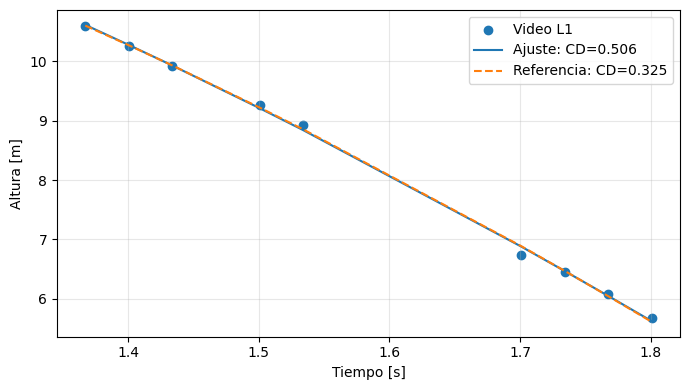

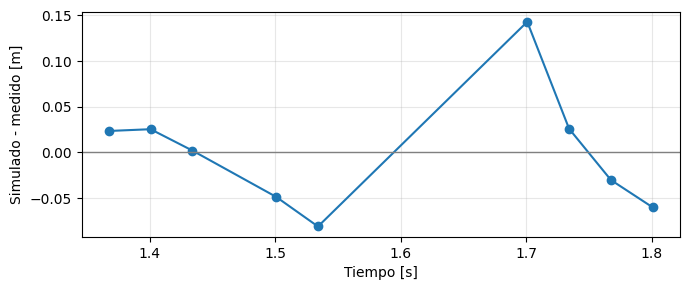

In [2]:
datos = pd.read_csv('datos_L1.csv')
datos = datos[(datos.good) & (datos.t >= 1.2)].copy()
t = datos.t.to_numpy()
y = datos.y.to_numpy()

masa, rho, Af = 0.0562, 1.226, 0.004418

def altura(k, y0, v0):
    def ecuacion(ti, estado):
        z, v = estado
        return [v, -9.81 - k * abs(v) * v]
    sol = solve_ivp(ecuacion, (0, t[-1]-t[0]), [y0, v0],
                    t_eval=t-t[0], max_step=0.03, rtol=1e-7, atol=1e-8)
    return sol.y[0]

v_inicial = np.polyfit(t, y, 1)[0]
ajuste = least_squares(lambda a: altura(*a) - y,
                       [0.015, y[0], v_inicial],
                       bounds=([0, -20, -80], [0.65, 50, 80]))
k, y0, v0 = ajuste.x
CD_L1 = 2 * masa * k / (rho * Af)
y_sim = altura(k, y0, v0)
rms = np.sqrt(np.mean((y_sim-y)**2))

k_ref = rho * Af * 0.325 / (2 * masa)
fijo = least_squares(lambda a: altura(k_ref, *a) - y,
                     [y[0], v_inicial], bounds=([-20, -80], [50, 80]))
y_ref = altura(k_ref, *fijo.x)
rms_ref = np.sqrt(np.mean((y_ref-y)**2))

print(f'L1: N={len(t)}, k={k:.7f} 1/m, CD={CD_L1:.3f}')
print(f'y0={y0:.3f} m, v0={v0:.3f} m/s')
print(f'RMS={rms:.5f} m, RMS con CD=0.325: {rms_ref:.5f} m')
print(f'Residuo máximo: {max(abs(y_sim-y)):.3f} m')

plt.figure(figsize=(7, 4))
plt.scatter(t, y, label='Video L1')
plt.plot(t, y_sim, label=f'Ajuste: CD={CD_L1:.3f}')
plt.plot(t, y_ref, '--', label='Referencia: CD=0.325')
plt.xlabel('Tiempo [s]')
plt.ylabel('Altura [m]')
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig('graficos/01_CD_L1.png', dpi=150)
plt.show()

plt.figure(figsize=(7, 3))
plt.plot(t, y_sim-y, 'o-')
plt.axhline(0, color='gray', linewidth=1)
plt.xlabel('Tiempo [s]')
plt.ylabel('Simulado - medido [m]')
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig('graficos/02_residuos_L1.png', dpi=150)
plt.show()

Para comprobar la sensibilidad del ajuste se fija cada $C_D$ y se vuelven a ajustar $y_0$ y $v_0$. No se informa un intervalo estadístico de confianza porque no se conoce con suficiente detalle la incertidumbre del seguimiento en píxeles.

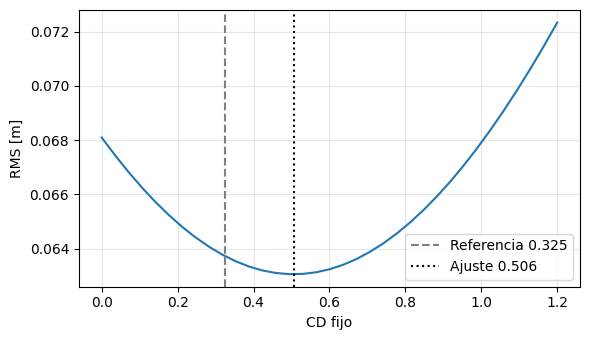

In [3]:
cd_prueba = np.linspace(0, 1.2, 35)
error_prueba = []
for cd in cd_prueba:
    k_prueba = rho * Af * cd / (2 * masa)
    a = least_squares(lambda q: altura(k_prueba, *q)-y,
                      [y[0], v_inicial], bounds=([-20, -80], [50, 80]))
    error_prueba.append(np.sqrt(np.mean(a.fun**2)))

plt.figure(figsize=(6, 3.5))
plt.plot(cd_prueba, error_prueba)
plt.axvline(0.325, color='gray', linestyle='--', label='Referencia 0.325')
plt.axvline(CD_L1, color='black', linestyle=':', label=f'Ajuste {CD_L1:.3f}')
plt.xlabel('CD fijo')
plt.ylabel('RMS [m]')
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig('graficos/03_sensibilidad_CD.png', dpi=150)
plt.show()

## 2. Convección externa
Se calculan velocidades entre posiciones sucesivas válidas y se aplica la correlación de placa plana del informe. Los cortes temporales corresponden a los tramos procesados en cada registro.

Vuelo  Pares   V_med   h_med    h_25    h_75     Bi
   L1      9 10.2769 18.6779 18.4302 19.2488 0.0156
   L2     80  4.1221 11.8292  9.5548 13.1873 0.0099
   L3      6  4.1084 11.7467 10.1924 13.0690 0.0098
   L4      5  2.5226  9.2539  6.9246 12.6427 0.0077
   L5     18  2.1502  8.5396  4.8391 12.1571 0.0071


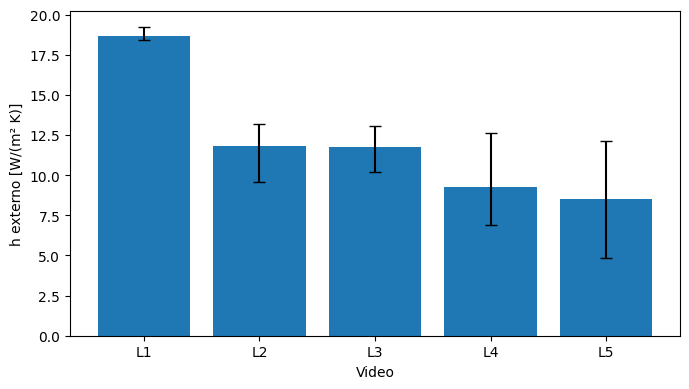

In [4]:
inicio = {'L1':0.0, 'L2':0.168, 'L3':0.167,
          'L4':0.167, 'L5':0.080}
filas = []
L, nu, Pr, k_aire = .45, 1.47e-5, .714, .02525
for vuelo, tmin in inicio.items():
    d = pd.read_csv(f'datos_corr_{vuelo.lower()}.csv')
    d = d[(d.good) & (d.t >= tmin)].sort_values('t')
    dt = np.diff(d.t)
    dx = np.diff(d.x_corrected)
    dy = np.diff(d.y)
    seleccion = dt < 0.12 if vuelo == 'L1' else dt > 0
    velocidad = np.hypot(dx[seleccion], dy[seleccion])/dt[seleccion]
    Re = velocidad*L/nu
    Nu = np.where(Re < 5e5, 0.664*np.sqrt(Re)*Pr**(1/3),
                  (0.037*Re**.8 - 871)*Pr**(1/3))
    h = Nu*k_aire/L
    filas.append([vuelo, len(h), np.median(velocidad), np.median(h),
                  *np.percentile(h, [25,75]), np.median(h)*.00025/.30])

h_tabla = pd.DataFrame(filas, columns=['Vuelo','Pares','V_med','h_med','h_25','h_75','Bi'])
print(h_tabla.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(h_tabla.Vuelo, h_tabla.h_med)
plt.errorbar(h_tabla.Vuelo, h_tabla.h_med,
             yerr=[h_tabla.h_med-h_tabla.h_25, h_tabla.h_75-h_tabla.h_med],
             fmt='none', ecolor='black', capsize=4)
plt.ylabel('h externo [W/(m² K)]')
plt.xlabel('Video')
plt.tight_layout()
plt.savefig('graficos/04_h_externo.png', dpi=150)
plt.show()

## 3. Modelo de las tres fases
Se reproduce el modelo de agua, aire y vuelo libre del grupo. Se usa $p_{amb}=101{,}35$ kPa, $C_D=0{,}325$ y se mantiene la presión inicial manométrica como parámetro. `rapido=True` reduce el muestreo para el barrido, manteniendo los mismos balances.

In [5]:
Vb = 0.0015
D, Dg, L = 0.075, 0.024, 0.45
Ag, Af = np.pi*Dg**2/4, np.pi*D**2/4
Ai = np.pi*D*L
rho_w, rho_inf = 1000., 1.226
Rgas, cv, gamma = 287., 717., 1.403
pamb, T0 = 101350., 289.15
nu, Pr, k_aire = 1.47e-5, 0.714, 0.02525
Cd, CD = 0.90, 0.325
sigma, emisividad = 5.67e-8, 0.90
Tcielo = 0.0552*T0**1.5


def simular(agua_ml=500, angulo=45, h_in=0, masa_seca=0.054, presion_bar=0.92, rapido=False):
    Vagua = agua_ml / 1e6
    Va0 = Vb - Vagua
    p0 = pamb + presion_bar * 1e5
    mg0 = p0 * Va0 / (Rgas*T0)
    ex, ey = np.cos(np.deg2rad(angulo)), np.sin(np.deg2rad(angulo))

    def calculo(estado, fase):
        x, y, vx, vy, Va, mg, Tg, Tw = estado
        Va, mg, Tg = max(Va, 1e-12), max(mg, 1e-12), max(Tg, 1)
        vel = np.hypot(vx, vy)
        Re = vel*L/nu
        if Re < 5e5:
            Nu = 0.664*np.sqrt(Re)*Pr**(1/3)
        else:
            Nu = (0.037*Re**0.8 - 871)*Pr**(1/3)
        hext = max(0, Nu*k_aire/L)
        hefectivo = hext/(1+hext*(0.00025/0.30))
        Qext = hefectivo*Ai*(T0-Tw)
        Qrad = emisividad*sigma*Ai*(Tcielo**4 - Tw**4)

        p = mg*Rgas*Tg/Va
        F = dVa = dmg = dTg = Qi = 0.
        magua = 0.
        if fase == 1:
            ve = np.sqrt(2*max(p-pamb, 0)/rho_w)
            dVa = Cd*Ag*ve
            F = rho_w*dVa*ve
            magua = rho_w*max(Vb-Va, 0)
            Qi = h_in*Ai*(Tw-Tg)
            dTg = (-p*dVa+Qi)/(mg*cv)
        elif fase == 2:
            p = mg*Rgas*Tg/Vb
            critico = ((gamma+1)/2)**(gamma/(gamma-1))
            mdot = 0.
            pe = pamb
            ve = 0.
            if p > pamb:
                if p/pamb >= critico:
                    mdot = Cd*Ag*p/np.sqrt(Tg)*np.sqrt(gamma/Rgas)*(2/(gamma+1))**((gamma+1)/(2*(gamma-1)))
                    pe = p*(2/(gamma+1))**(gamma/(gamma-1))
                    ve = np.sqrt(gamma*Rgas*Tg*2/(gamma+1))
                else:
                    q = pamb/p
                    mdot = Cd*Ag*p*np.sqrt(2*gamma/((gamma-1)*Rgas*Tg))*np.sqrt(max(q**(2/gamma)-q**((gamma+1)/gamma), 0))
                    ve = np.sqrt(max(2*gamma*Rgas*Tg/(gamma-1)*(1-q**((gamma-1)/gamma)), 0))
            dmg = -mdot
            F = mdot*ve+(pe-pamb)*Ag
            Qi = h_in*Ai*(Tw-Tg)
            dTg = (-mdot*Rgas*Tg+Qi)/(mg*cv)
        else:
            magua = rho_w*max(Vb-Va, 0)

        m = masa_seca + magua + mg
        Cw = 0.052*1250 + 0.002*1250 + magua*4180
        dTw = (-Qi+Qext+Qrad)/Cw
        ax = (F*ex - 0.5*rho_inf*CD*Af*vel*vx)/m
        ay = (F*ey - 0.5*rho_inf*CD*Af*vel*vy)/m-9.81
        return [vx, vy, ax, ay, dVa, dmg, dTg, dTw], F, p, hext

    def ec(t, estado, fase):
        return calculo(estado, fase)[0]

    def fin_agua(t, estado):
        return Vb-estado[4]
    fin_agua.terminal, fin_agua.direction = True, -1

    def fin_presion(t, estado):
        return estado[5]*Rgas*estado[6]/max(estado[4], 1e-12)-pamb
    fin_presion.terminal, fin_presion.direction = True, -1

    def fin_aire(t, estado):
        return estado[5]*Rgas*estado[6]/Vb-pamb*1.001
    fin_aire.terminal, fin_aire.direction = True, -1

    def fin_suelo(t, estado):
        return estado[1]
    fin_suelo.terminal, fin_suelo.direction = True, -1

    estado = np.array([0., 0., 0., 0., Va0, mg0, T0, T0])
    partes = []
    sol = solve_ivp(lambda t,s: ec(t,s,1), (0,25), estado,
                    events=[fin_agua, fin_presion], dense_output=True,
                    max_step=(.02 if rapido else .002), rtol=(2e-7 if rapido else 1e-8), atol=(1e-9 if rapido else 1e-10))
    partes.append((1,sol))
    if len(sol.t_events[0]):
        estado = sol.y[:,-1].copy()
        estado[4] = Vb
        sol = solve_ivp(lambda t,s: ec(t,s,2), (sol.t[-1],25), estado,
                        events=fin_aire, dense_output=True,
                        max_step=(.02 if rapido else .002), rtol=(2e-7 if rapido else 1e-8), atol=(1e-9 if rapido else 1e-10))
        partes.append((2,sol))

    estado = sol.y[:,-1]
    sol = solve_ivp(lambda t,s: ec(t,s,3), (sol.t[-1],25), estado,
                    events=fin_suelo, dense_output=True,
                    max_step=(.02 if rapido else .002), rtol=(2e-7 if rapido else 1e-8), atol=(1e-9 if rapido else 1e-10))
    partes.append((3,sol))

    if rapido:
        return {'R': float(partes[-1][1].y[0, -1]),
                'H': float(max(s.y[1].max() for fase, s in partes))}

    filas = []
    for fase, sol in partes:
        tiempos = np.append(np.arange(sol.t[0], sol.t[-1], .005),sol.t[-1])
        for ti in tiempos:
            s = sol.sol(ti)
            _, fuerza, presion, h = calculo(s, fase)
            filas.append((ti,fase,s[0],s[1],s[6],fuerza,presion,h))
    return pd.DataFrame(filas, columns=['t','fase','x','y','Tg','F','p','hext'])

## 4. Convección interna y exergía
Los dos casos se comparan con la misma carga inicial, el mismo ángulo y la misma presión.

hi=0: alcance=21.12 m, Tg mínima=240.47 K, impulso=4.48 N s
hi=5000: alcance=31.88 m, Tg mínima=280.85 K, impulso=5.23 N s


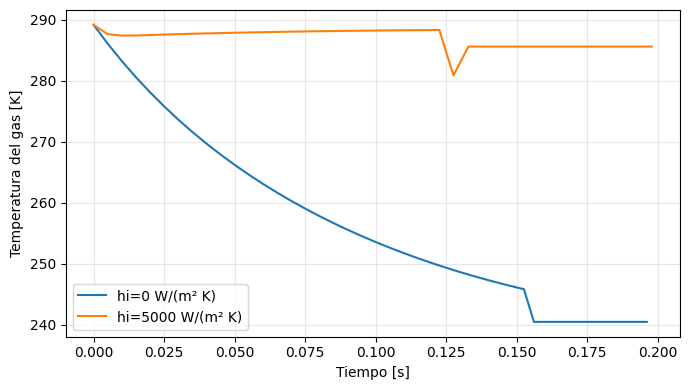

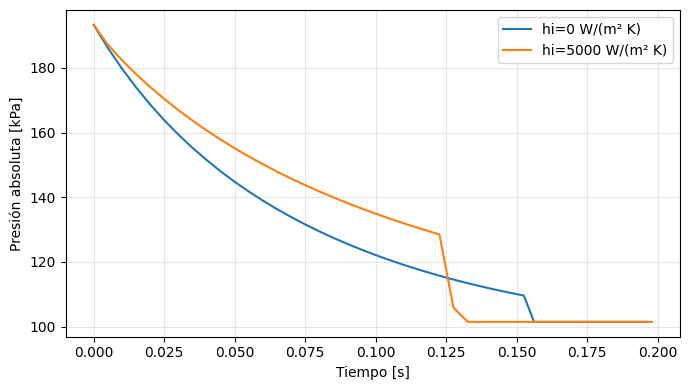

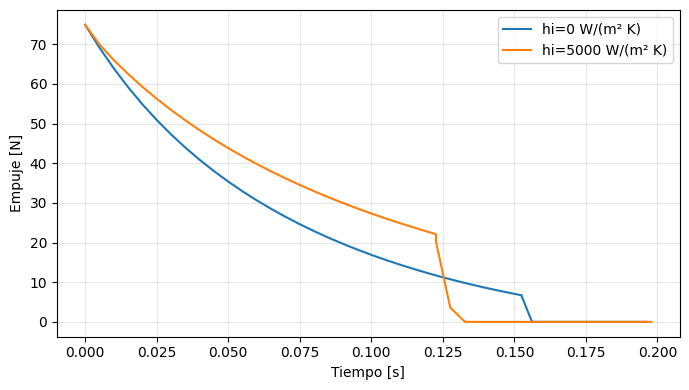

p_man=0.92 bar: Ex0=32.89 J, R=21.12 m, eta=47.2%
p_man=1.10 bar: Ex0=45.33 J, R=29.13 m, eta=47.3%
p_man=4.00 bar: Ex0=401.52 J, R=89.05 m, eta=16.3%


In [6]:
casos = {hi: simular(500, 45, hi) for hi in [0, 5000]}
for hi, d in casos.items():
    print(f'hi={hi}: alcance={d.x.iloc[-1]:.2f} m, '          f'Tg mínima={d.Tg.min():.2f} K, impulso={trapezoid(d.F,d.t):.2f} N s')
for variable, nombre, escala, unidad in [
    ('Tg','05_temperatura',1,'Temperatura del gas [K]'),
    ('p','06_presion',1e3,'Presión absoluta [kPa]'),
    ('F','07_empuje',1,'Empuje [N]')]:
    plt.figure(figsize=(7, 4))
    for hi, d in casos.items():
        d = d[d.t <= .20]
        plt.plot(d.t, d[variable]/escala, label=f'hi={hi} W/(m² K)')
    plt.xlabel('Tiempo [s]')
    plt.ylabel(unidad)
    plt.legend()
    plt.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(f'graficos/{nombre}.png', dpi=150)
    plt.show()

# Exergía del aire comprimido
p_amb = 101350
Vaire = .001  # botella de 1.5 L con 500 mL de agua
for presion in [.92, 1.10, 4.0]:
    p0 = p_amb + presion*1e5
    ex0 = p0*Vaire*np.log(p0/p_amb)-(p0-p_amb)*Vaire
    d = simular(500,45,0,presion_bar=presion,rapido=True)
    eta = d['R']*.150*9.81/(2*ex0)
    print(f'p_man={presion:.2f} bar: Ex0={ex0:.2f} J, R={d["R"]:.2f} m, eta={100*eta:.1f}%')

## 5. Barrido de 420 configuraciones e índice proyectado $J^*$
Los cinco apogeos provienen del análisis de videos; L1 y L3 son extrapolaciones. Se calculan las presiones equivalentes con el modelo vertical, **no son presiones medidas**. El índice conserva los pesos del enunciado, pero no reemplaza el índice experimental basado en alcances horizontales repetidos.

In [7]:
apogeos = np.array([13.03, 7.45, 7.74, 9.98, 11.27])  # L1 a L5, m
presiones = np.array([
    brentq(lambda p: simular(500,90,0,presion_bar=p,rapido=True)['H']-h,
           .5,1.3,xtol=1e-5)
    for h in apogeos
])
print('Presiones equivalentes [bar man]:', np.round(presiones, 3))

resultados = []
for masa_seca in [.054,.064,.074]:
    for agua_ml in range(150, 1126, 75):
        for angulo in range(25, 71, 5):
            nominal = simular(agua_ml,angulo,0,masa_seca,rapido=True)['R']
            variaciones = np.array([
                simular(agua_ml,angulo,0,masa_seca,float(p),rapido=True)['R']
                for p in presiones
            ])
            Va = .0015 - agua_ml/1e6
            p0 = p_amb + .92*1e5
            ex0 = Va*(p0*np.log(p0/p_amb)-(p0-p_amb))
            eta = nominal*.150*9.81/(2*ex0)
            cv_alcance = np.std(variaciones,ddof=1)/np.mean(variaciones)
            error = np.mean(np.abs(nominal-variaciones)/variaciones)
            resultados.append([agua_ml,angulo,masa_seca,nominal,eta,cv_alcance,error,*variaciones])

campos = ['Agua','Angulo','Masa','R','eta','CV','Error']+[f'R{i}' for i in range(1,6)]
barrido = pd.DataFrame(resultados,columns=campos)
Rmax, eta_max = barrido.R.max(), barrido.eta.max()

def calcular_J(df, columnas=None, limite_cv=.20, limite_error=.25):
    if columnas is None:
        columnas = [f'R{i}' for i in range(1,6)]
    rangos = df[columnas].to_numpy()
    cv = rangos.std(axis=1,ddof=1)/rangos.mean(axis=1)
    e = np.mean(np.abs(df.R.to_numpy()[:,None]-rangos)/rangos,axis=1)
    return (.40*df.eta/eta_max+.15*df.R/Rmax
            +.15*np.clip(1-cv/limite_cv,0,1)
            +.30*np.clip(1-e/limite_error,0,1))

barrido['J'] = calcular_J(barrido)
barrido.to_csv('barrido_420.csv',index=False)
mejor = barrido.loc[barrido.J.idxmax()]
print(f'{len(barrido)} diseños. R máximo={Rmax:.3f} m; eta máxima={100*eta_max:.2f}%')
print('Máximo J*:', mejor[['Agua','Angulo','Masa','R','eta','CV','Error','J']].to_dict())
print('\nDiseños de la tabla:')
casos_tabla = [(300,45),(300,40),(375,45),(150,40),(600,40)]
for agua, angulo in casos_tabla:
    r = barrido[(barrido.Agua==agua)&(barrido.Angulo==angulo)&(barrido.Masa==.054)].iloc[0]
    print(f'{agua:3} mL, {angulo}°: R={r.R:.2f} m, eta={100*r.eta:.2f}%, '
          f'CV*={100*r.CV:.2f}%, error*={100*r.Error:.2f}%, J*={r.J:.4f}')

Presiones equivalentes [bar man]: [0.982 0.798 0.806 0.877 0.92 ]


420 diseños. R máximo=29.528 m; eta máxima=55.79%
Máximo J*: {'Agua': 300.0, 'Angulo': 45.0, 'Masa': 0.054, 'R': 29.51374632479719, 'eta': 0.5502018907468307, 'CV': 0.10303242048389596, 'Error': 0.0958179030486229, 'J': 0.8021281357726263}

Diseños de la tabla:
300 mL, 45°: R=29.51 m, eta=55.02%, CV*=10.30%, error*=9.58%, J*=0.8021
300 mL, 40°: R=29.53 m, eta=55.05%, CV*=10.50%, error*=9.78%, J*=0.7986
375 mL, 45°: R=28.06 m, eta=55.79%, CV*=11.97%, error*=11.26%, J*=0.7676
150 mL, 40°: R=25.51 m, eta=42.27%, CV*=9.87%, error*=9.13%, J*=0.6990
600 mL, 40°: R=9.59 m, eta=23.84%, CV*=36.05%, error*=38.26%, J*=0.2196


## 6. Comprobaciones y gráficos del diseño
Se comprueba qué ocurre al excluir un apogeo extrapolado y al variar los umbrales del índice. También se contrasta el alcance de referencia con el que resultaría de usar $C_D=0{,}506$.

Sin L1: 300 mL, 45°, 0.054 kg, J*=0.8103
Sin L3: 300 mL, 45°, 0.054 kg, J*=0.8262
Solo apogeos observados: 300 mL, 45°, 0.054 kg, J*=0.8344
Mismo diseño en los 9 cambios de umbrales: True


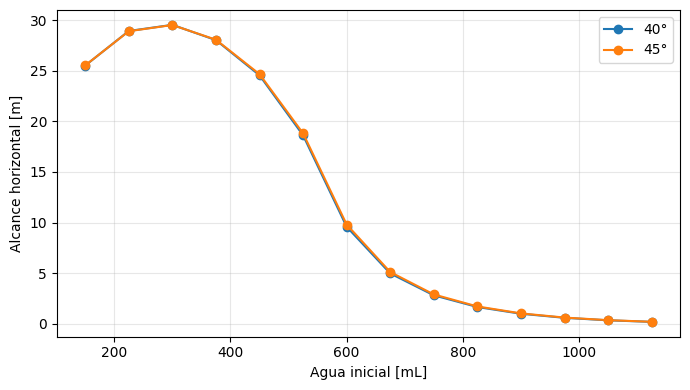

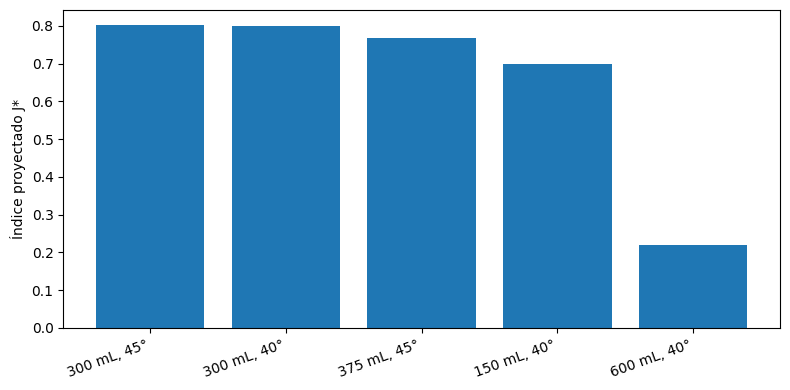

300 mL, 45°: R con CD=0.325: 29.51 m; con CD=0.506: 25.41 m


In [8]:
for nombre, columnas in [
    ('Sin L1',['R2','R3','R4','R5']),
    ('Sin L3',['R1','R2','R4','R5']),
    ('Solo apogeos observados',['R2','R4','R5'])]:
    J = calcular_J(barrido,columnas)
    fila = barrido.loc[J.idxmax()]
    print(f'{nombre}: {int(fila.Agua)} mL, {int(fila.Angulo)}°, '
          f'{fila.Masa:.3f} kg, J*={J.max():.4f}')

coinciden = True
for umbral_cv in [.15,.20,.25]:
    for umbral_error in [.20,.25,.30]:
        J = calcular_J(barrido,limite_cv=umbral_cv,limite_error=umbral_error)
        fila = barrido.loc[J.idxmax()]
        coinciden &= (fila.Agua==300 and fila.Angulo==45 and fila.Masa==.054)
print('Mismo diseño en los 9 cambios de umbrales:', coinciden)

plt.figure(figsize=(7,4))
for angulo in [40,45]:
    datos_agua = barrido[(barrido.Masa==.054)&(barrido.Angulo==angulo)]
    plt.plot(datos_agua.Agua, datos_agua.R,'o-',label=f'{angulo}°')
plt.xlabel('Agua inicial [mL]')
plt.ylabel('Alcance horizontal [m]')
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig('graficos/08_agua_alcance.png',dpi=150)
plt.show()

etiquetas = [f'{a} mL, {t}°' for a,t in casos_tabla]
valores = [barrido[(barrido.Agua==a)&(barrido.Angulo==t)&
                   (barrido.Masa==.054)].J.iloc[0] for a,t in casos_tabla]
plt.figure(figsize=(8,4))
plt.bar(etiquetas,valores)
plt.xticks(rotation=20,ha='right')
plt.ylabel('Índice proyectado J*')
plt.tight_layout()
plt.savefig('graficos/09_indice_J.png',dpi=150)
plt.show()

# Se modifica únicamente el CD del modelo para esta comprobación.
CD = .325
R_teorico = simular(300,45,rapido=True)['R']
CD = CD_L1
R_ajustado = simular(300,45,rapido=True)['R']
CD = .325
print(f'300 mL, 45°: R con CD=0.325: {R_teorico:.2f} m; '
      f'con CD={CD_L1:.3f}: {R_ajustado:.2f} m')